In [1]:
import socket
from pyspark.sql import SparkSession

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pyspark.sql.functions as F
import seaborn as sns

import os
import sys

In [2]:
spark = SparkSession.builder.getOrCreate()

spark.conf.set("spark.sql.session.timeZone", "Asia/Singapore")

print("Running on:   ", socket.gethostname())
print("Spark master: ", spark.sparkContext.master)
print("Spark version:", spark.version)

Running on:    rainfall-dev-m
Spark master:  yarn
Spark version: 3.5.3


In [3]:
## Constants
sns.set_theme()

C_LAT, C_LON = 1.3521, 103.8198 
RF_MULTIPLIER = (24 * 60) / 5

In [4]:
rain = spark.read.parquet("gs://dsa5208-rainfall-sixing-data/parquet/")

In [5]:
rain.select("reading_value", "location_latitude", "location_longitude") \
    .summary("count", "mean", "min", "max").show()

+-------+--------------------+------------------+------------------+
|summary|       reading_value| location_latitude|location_longitude|
+-------+--------------------+------------------+------------------+
|  count|            48538713|          48538713|          48538713|
|   mean|0.025303765871258124|1.3455907687398532|103.82069359976731|
|    min|                 0.0|             1.189|         103.61843|
|    max|                37.2|           1.45817|          104.0307|
+-------+--------------------+------------------+------------------+



In [7]:
rain.agg(F.countDistinct("station_id"), F.countDistinct("station_name"), F.countDistinct("station_name_clean"),
       F.countDistinct("station_device_id")).show()

rain.groupBy("station_id", "station_name_clean").count().orderBy("count").show(70, truncate=False)

+--------------------------+----------------------------+----------------------------------+---------------------------------+
|count(DISTINCT station_id)|count(DISTINCT station_name)|count(DISTINCT station_name_clean)|count(DISTINCT station_device_id)|
+--------------------------+----------------------------+----------------------------------+---------------------------------+
|                        91|                         117|                                90|                               91|
+--------------------------+----------------------------+----------------------------------+---------------------------------+



+----------+---------------------------+------+
|station_id|station_name_clean         |count |
+----------+---------------------------+------+
|S97       |Pioneer Sector 2           |6     |
|S72       |Prince Edward Road         |33    |
|S103      |Dairy Farm Road            |45    |
|S110      |Serangoon North Avenue 4   |27573 |
|S96       |Tanah Merah Coast Road     |30633 |
|S24B      |Upper Changi Road North    |32648 |
|S06       |Paya Lebar                 |40141 |
|S63       |International Road         |93890 |
|S105      |Admiralty Road West        |109009|
|S101      |Corporation Road           |169959|
|S102      |Semakau Landfill           |181592|
|S55       |Buangkok Green             |206417|
|S36       |Upper Serangoon Road       |270637|
|S202      |S202                       |276164|
|S205      |S205                       |315754|
|S204      |S204                       |345437|
|S91       |Yishun Avenue 5            |346468|
|S46       |Sime Road                  |

In [8]:
(rain.select("station_id", "station_name_clean").distinct()
     .groupBy("station_name_clean")
     .agg(F.count("*").alias("n_ids"),
          F.collect_set("station_id").alias("ids"))
     .filter(F.col("n_ids") > 1)
     .show(truncate=False))

+-----------------------+-----+-----------+
|station_name_clean     |n_ids|ids        |
+-----------------------+-----+-----------+
|Upper Changi Road North|2    |[S24, S24B]|
+-----------------------+-----+-----------+



### Graphs and Charts

In [9]:
#df = spark.read.option("header", True).csv(DATA)
#rain = spark.read.parquet("gs://dsa5208-rainfall-sixing-data/parquet/")
rain = rain.withColumn("date", F.to_date("date", "yyyy-MM-dd"))
rain = rain.withColumn("year", F.year("date")).withColumn("month", F.month("date"))

monthly_spk = (rain.groupBy("year", "month")
    .agg(F.avg("reading_value").alias("mean_per_interval"),
         F.countDistinct("station_id").alias("n_stations"))
    .withColumn("year_month", F.make_date("year", "month", F.lit(1)))
    .withColumn("days", F.dayofmonth(F.last_day("year_month")))
    .withColumn("avg_rainfall_monthly",
                F.col("mean_per_interval") * F.col("days") * RF_MULTIPLIER)
    .orderBy("year_month"))

In [10]:
monthly_df = monthly_spk.toPandas()
monthly_df

,year,month,mean_per_interval,n_stations,year_month,days,avg_rainfall_monthly
0,2017,1,0.027649,58,2017-01-01,31,246.847136
1,2017,2,0.018776,58,2017-02-01,28,151.410304
2,2017,3,0.020656,59,2017-03-01,31,184.414851
3,2017,4,0.028492,55,2017-04-01,30,246.170041
4,2017,5,0.026978,52,2017-05-01,31,240.860586
...,...,...,...,...,...,...,...
91,2024,8,0.014338,63,2024-08-01,31,128.012822
92,2024,9,0.026012,62,2024-09-01,30,224.740843
93,2024,10,0.021529,62,2024-10-01,31,192.209064
94,2024,11,0.048195,64,2024-11-01,30,416.407206


### Time Series Graph

This chart plots the estimated monthly rainfall for each region from 2017 to 2024, giving an overview of Singapore's rainfall over the full period. Viewing the regions together makes it possible to see any seasonality or cyclical patterns that may occur. 

<Figure size 1600x1000 with 0 Axes>

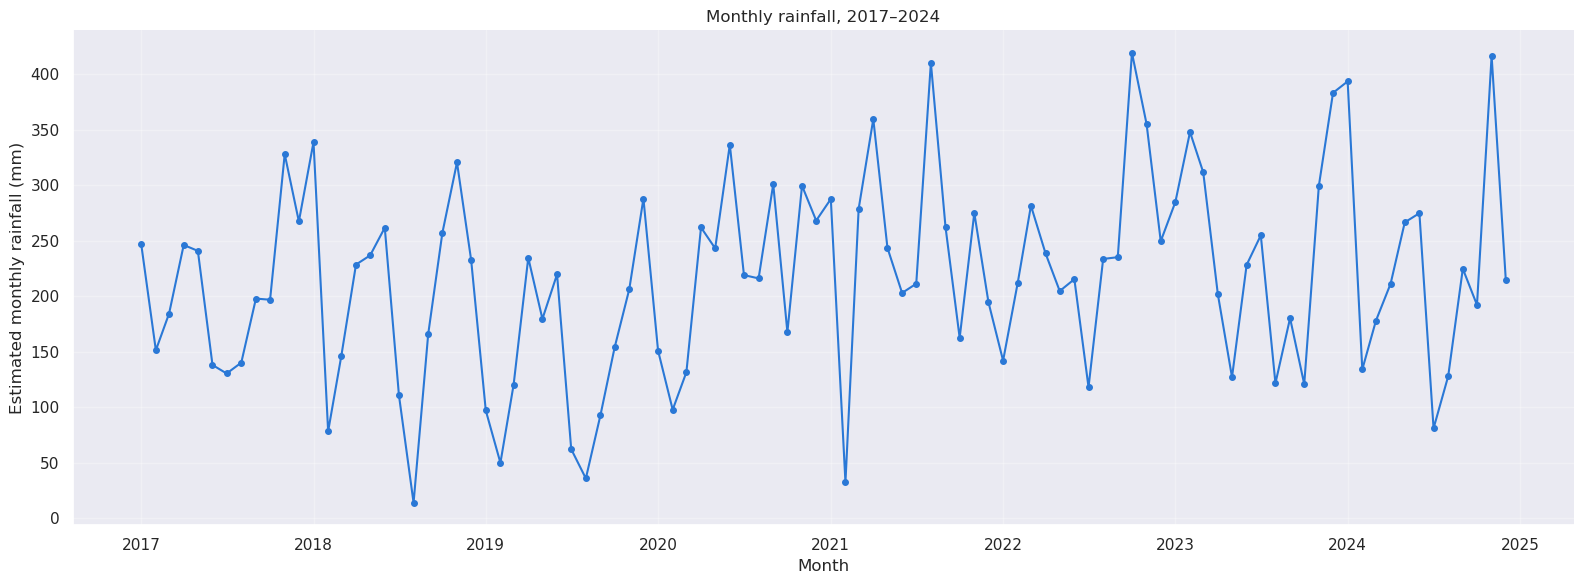

In [11]:
plt.figure(figsize=(16, 10))

monthly_df = monthly_df.sort_values("year_month")

fig, ax = plt.subplots(figsize=(16, 6))
ax.plot(monthly_df["year_month"], monthly_df["avg_rainfall_monthly"],
        marker="o", markersize=4, linewidth=1.5, color="#2a78d6")

ax.set_xlabel("Month")
ax.set_ylabel("Estimated monthly rainfall (mm)")
ax.set_title("Monthly rainfall, 2017–2024")
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.xaxis.set_minor_locator(mdates.MonthLocator(bymonth=[4, 7, 10]))
ax.grid(True, alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()

### Annual Rainfall Bar Chart

This chart shows the estimated annual rainfall for each year from 2017 to 2024, with the number of reporting stations annotated on each bar. The estimate is derived from the mean rainfall per five-minute interval and scaled to a full year, so it is not distorted by changes in how many stations were active. Showing the station count alongside each bar makes that coverage explicit, so any year-to-year difference can be attributed to rainfall rather than to the size of the monitoring network.

In [12]:
annual_spk = (rain.groupBy("year")
    .agg(F.avg("reading_value").alias("mean_per_interval"),
         F.countDistinct("station_id").alias("n_stations"))
    .withColumn("days", F.when(F.col("year") % 4 == 0, 366).otherwise(365))
    .withColumn("est_annual_mm",
                F.col("mean_per_interval") * F.col("days") * 288)
    .orderBy("year"))

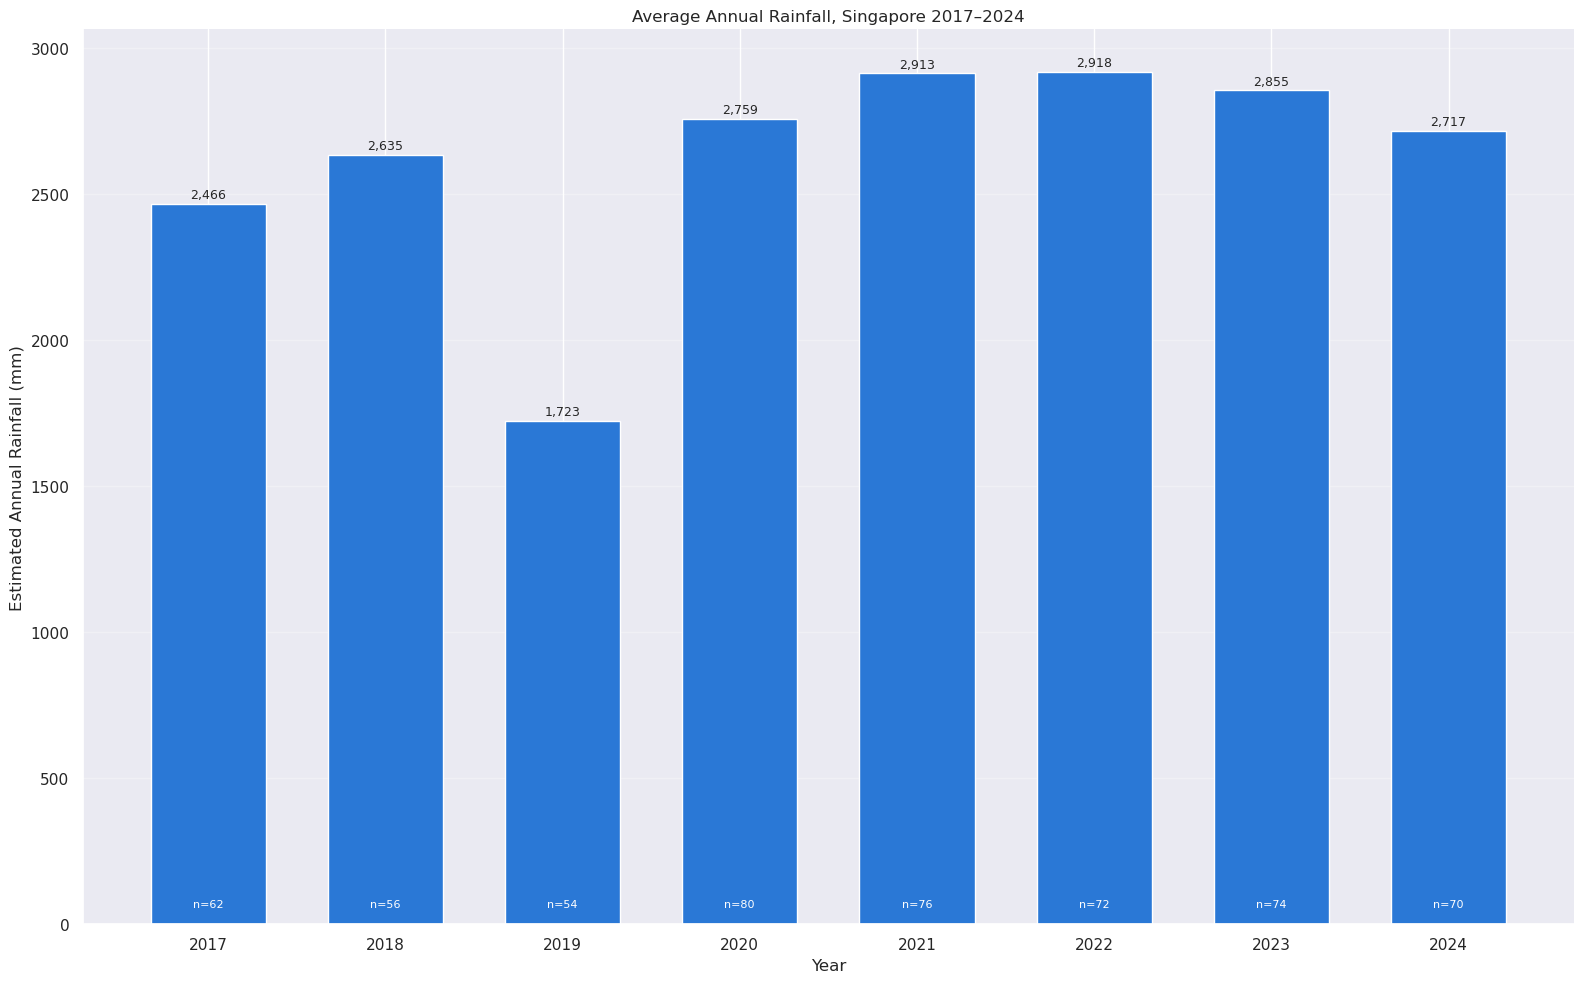

In [13]:
annual_df = annual_spk.toPandas()

fig, ax = plt.subplots(figsize=(16, 10))
bars = ax.bar(annual_df["year"], annual_df["est_annual_mm"],
              color="#2a78d6", width=0.65)

ax.set_xlabel("Year")
ax.set_ylabel("Estimated Annual Rainfall (mm)")
ax.set_title("Average Annual Rainfall, Singapore 2017–2024")
ax.set_xticks(annual_df["year"])
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

for b, v, n in zip(bars, annual_df["est_annual_mm"], annual_df["n_stations"]):
    ax.text(b.get_x() + b.get_width() / 2, v + 20, f"{v:,.0f}",
            ha="center", fontsize=9)
    ax.text(b.get_x() + b.get_width() / 2, 60, f"n={n}",
            ha="center", fontsize=8, color="white")

plt.tight_layout()

### Region Test

In [16]:
stations_spk = rain.select("station_id", "station_name_clean", "location_latitude", "location_longitude").distinct()

In [17]:
stations_df = stations_spk.toPandas()
stations_df

,station_id,station_name_clean,location_latitude,location_longitude
0,S120,Holland Road,1.30874,103.81800
1,S218,Bukit Batok Street 34,1.36491,103.75065
2,S77,Alexandra Road,1.29370,103.81250
3,S222,Henderson Road,1.28987,103.82364
4,S71,Kent Ridge Road,1.29230,103.78150
...,...,...,...,...
87,S72,Prince Edward Road,1.27400,103.84820
88,S24B,Upper Changi Road North,1.36780,103.99800
89,S06,Paya Lebar,1.35240,103.90070
90,S96,Tanah Merah Coast Road,1.31750,104.03070


In [18]:
stations_spk = rain.select("station_id", "station_name_clean", "location_latitude", "location_longitude").distinct()

stations = (stations_spk
    .withColumn("dy", F.col("location_latitude") - F.lit(C_LAT))
    .withColumn("dx", F.col("location_longitude") - F.lit(C_LON))
    .withColumn("dist", F.sqrt(F.col("dx")**2 + F.col("dy")**2))
    .withColumn("bearing", F.degrees(F.atan2("dx", "dy")))  # 0=N, 90=E
    .withColumn("region",
        F.when(F.col("dist") < 0.045, "Central")
         .when((F.col("bearing") >= -45) & (F.col("bearing") < 45), "North")
         .when((F.col("bearing") >= 45) & (F.col("bearing") < 135), "East")
         .when((F.col("bearing") >= -135) & (F.col("bearing") < -45), "West")
         .otherwise("South")))

In [20]:
region_spk = rain.join(stations.select("station_id", "region"), on="station_id", how="left")

In [21]:
station_monthly = (region_spk
    .groupBy("station_id", "region", "year", "month")
    .agg(F.sum("reading_value").alias("monthly_mm")))

region_monthly = (station_monthly
    .groupBy("region", "year", "month")
    .agg(F.avg("monthly_mm").alias("avg_mm"),
         F.countDistinct("station_id").alias("n_stations"))
    .withColumn("ym", F.make_date("year", "month", F.lit(1)))
    .orderBy("ym", "region"))

region_df = region_monthly.toPandas()

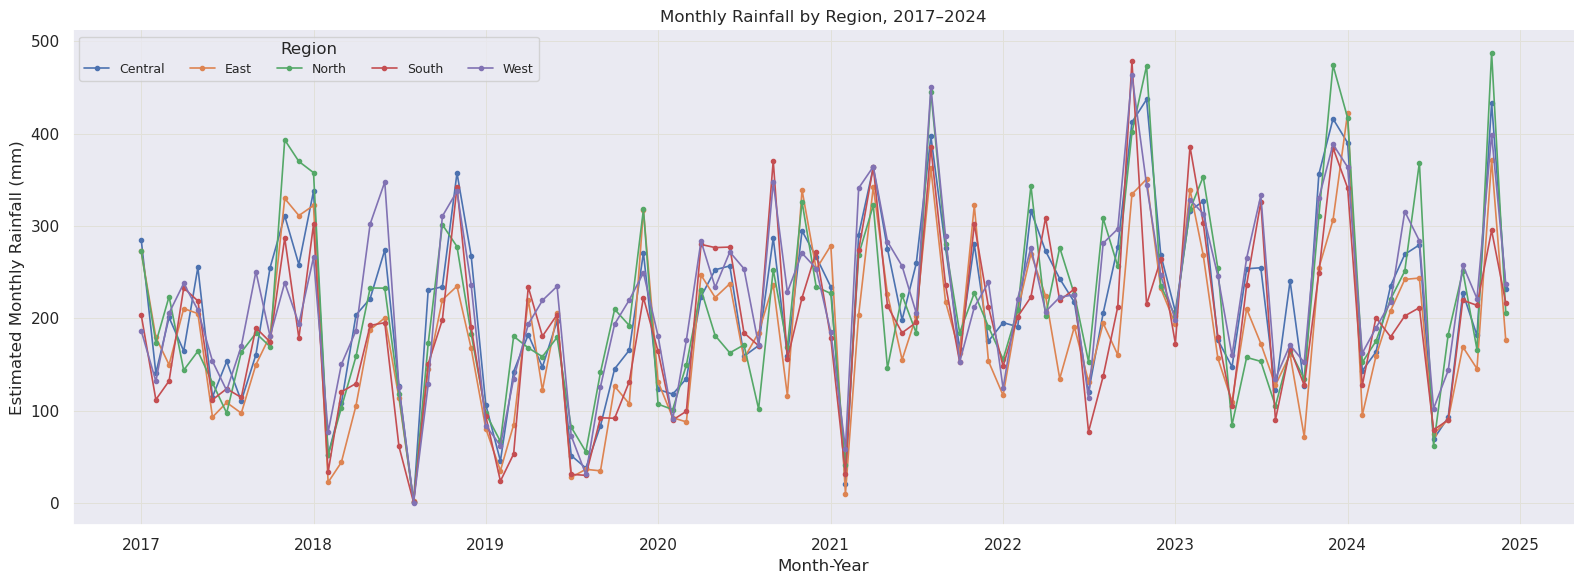

In [22]:
region_df = region_df.sort_values("ym")
wide = region_df.pivot(index="ym", columns="region", values="avg_mm")

fig, ax = plt.subplots(figsize=(16, 6))
wide.plot(ax=ax, marker="o", markersize=3, linewidth=1.2)

ax.set_xlabel("Month-Year")
ax.set_ylabel("Estimated Monthly Rainfall (mm)")
ax.set_title("Monthly Rainfall by Region, 2017–2024")
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.grid(which="major", axis="both", color="#e1e0d9", linewidth=0.7)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(title="Region", ncol=5, fontsize=9)
plt.tight_layout()

array([<Axes: xlabel='ym'>, <Axes: xlabel='ym'>, <Axes: xlabel='ym'>,
       <Axes: xlabel='ym'>, <Axes: xlabel='ym'>], dtype=object)

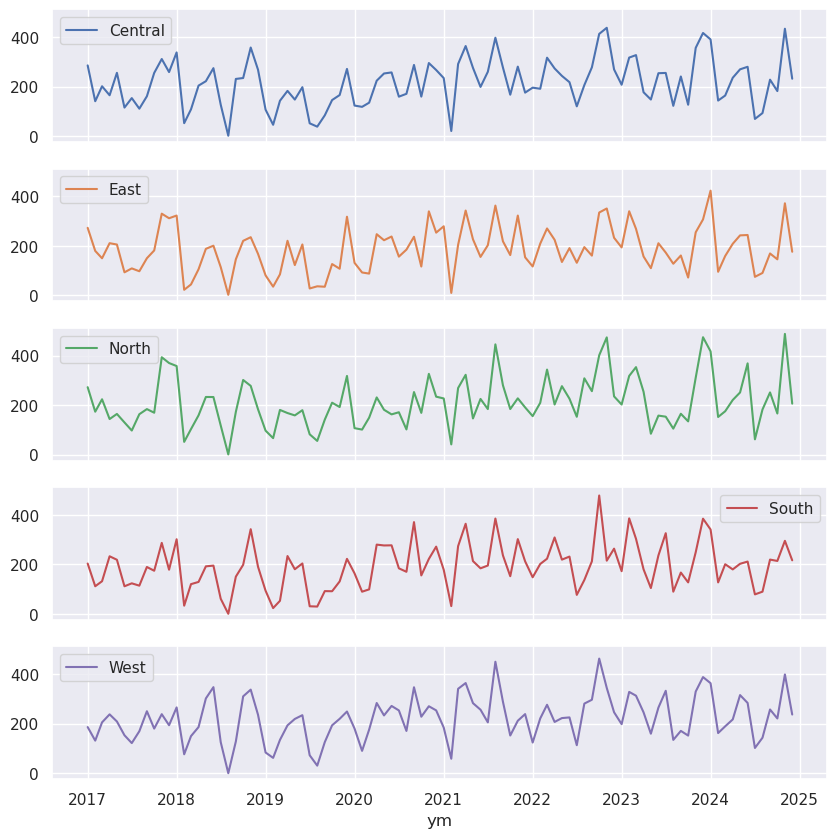

In [23]:
wide = region_df.pivot(index="ym", columns="region", values="avg_mm")
wide.plot(subplots=True, figsize=(10,10), sharex=True, sharey=True)

In [24]:
stations.groupBy("region").agg(F.count("*").alias("n"),
         F.round(F.avg("location_latitude"), 4).alias("mean_lat"),
         F.round(F.avg("location_longitude"), 4).alias("mean_lon")).orderBy(F.desc("n")).show()

+-------+---+--------+--------+
| region|  n|mean_lat|mean_lon|
+-------+---+--------+--------+
|   East| 30|  1.3488|103.9232|
|   West| 23|  1.3413|103.7139|
|  South| 15|  1.2801|103.8134|
|Central| 13|  1.3446|103.8263|
|  North| 11|  1.4305|103.8006|
+-------+---+--------+--------+



### Heatmap Per Month

This heatmap combines all readings from 2017 to 2024 to show the mean rainfall for each of hour of day and calendar month. The aim is to
identify the wettest hours of the day and whether that daily pattern shifts across the seasons. Averaging over eight years smoothens out year-to-year variation, so what remains is the underlying climatological cycle rather than the behaviour of any single year.

In [25]:
hm = (rain
    .withColumn("hour", F.hour("timestamp"))
    .groupBy("month", "hour")
    .agg(F.avg("reading_value").alias("mean_mm"),
         F.count("*").alias("n"))
    .orderBy("month", "hour"))

hm_df = hm.toPandas()
grid = hm_df.pivot(index="hour", columns="month", values="mean_mm")

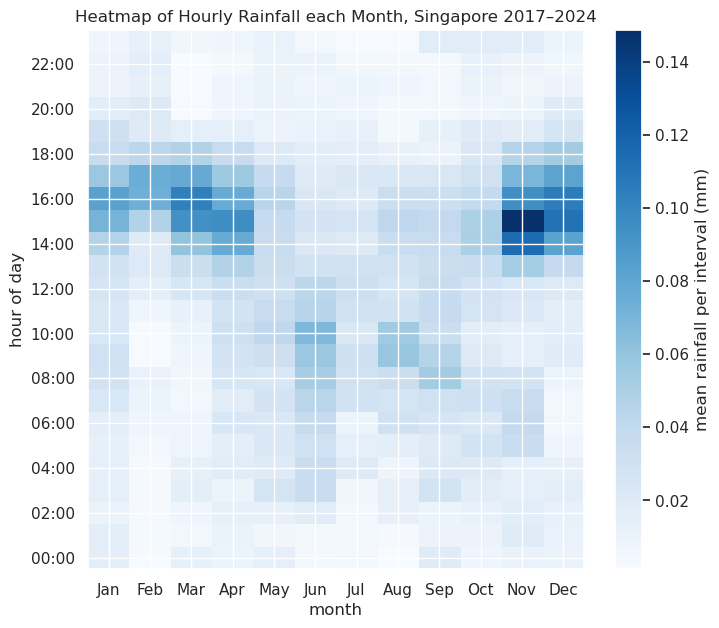

In [26]:
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(grid.values, aspect="auto", origin="lower", cmap="Blues")
ax.set_title("Heatmap of Hourly Rainfall each Month, Singapore 2017–2024")
ax.set_xticks(range(12), ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
ax.set_yticks(range(0, 24, 2), [f"{h:02d}:00" for h in range(0, 24, 2)])
ax.set_xlabel("month"); ax.set_ylabel("hour of day")
fig.colorbar(im, label="mean rainfall per interval (mm)")